# 05 Walk-forward evaluation and cost-cap analysis

**Question.** Can we predict who wins a Formula 1 race using only information known before it starts,
and does a model trained before the 2021 cost cap still work after it?

Input: `data/processed/model_table.csv` (notebook 04). All the logic is in `src/modeling.py`;
the figures come from `src/plots.py` and are saved in `figures/`, the tables in `tables/`.

**Method in one paragraph.** Logistic regression on one row per driver per race (target: the driver wins).
Each season from 2017 to 2026 is predicted by a model trained on **earlier seasons only** (walk-forward, no random split).
Performance is measured with AUC and log-loss and compared with a pole-sitter baseline.
Intervals come from a bootstrap that resamples whole races.

In [10]:
import sys
from pathlib import Path

cwd = Path.cwd()
root = next(p for p in [cwd, cwd / "AdvanceData", *cwd.parents] if (p / "src").is_dir())
sys.path.insert(0, str(root / "src"))

import pandas as pd
import modeling
import plots

In [11]:
data = modeling.load_model_table()
main = modeling.MAIN_FEATURES          # grid, driver form, driver wins, team pace (project specification)
print(data.shape, "rows;", data["race_id"].nunique(), "races;", data["year"].min(), "-", data["year"].max())
print("main model features:", main)

(5545, 16) rows; 272 races; 2014 - 2026
main model features: ['grid', 'driver_form3', 'driver_wins_before', 'team_pace3']


## 1. Walk-forward evaluation

Each row is a test season. **AUC** is the probability that a random winner gets a higher predicted probability than a random non-winner
(0.5 = chance, 1 = perfect). **Log-loss** penalises confident wrong predictions (lower is better).
**top_pick_hit** is the share of races won by the driver with the highest predicted probability.
The *pole-sitter baseline* predicts from the starting grid only: it uses the win rate of pole-sitters and of the other drivers in the training seasons.

,year,period,AUC,log_loss,top_pick_hit,AUC_pole,log_loss_pole,pole_hit
0,2017,pre-cap,0.938,0.121,0.450,0.940,0.141,0.550
1,2018,pre-cap,0.943,0.114,0.524,0.922,0.156,0.476
2,2019,pre-cap,0.956,0.103,0.524,0.955,0.174,0.381
3,2020,pre-cap,0.943,0.103,0.647,0.923,0.134,0.588
4,2021,post-cap,0.934,0.124,0.455,0.921,0.150,0.500
5,2022,post-cap,0.924,0.126,0.364,0.900,0.159,0.455
6,2023,post-cap,0.982,0.074,0.818,0.941,0.125,0.636
7,2024,post-cap,0.932,0.120,0.500,0.919,0.159,0.458
8,2025,extension 2025,0.969,0.097,0.458,0.971,0.119,0.667
9,2026,2026 new rules,0.942,0.107,0.500,0.938,0.104,0.700


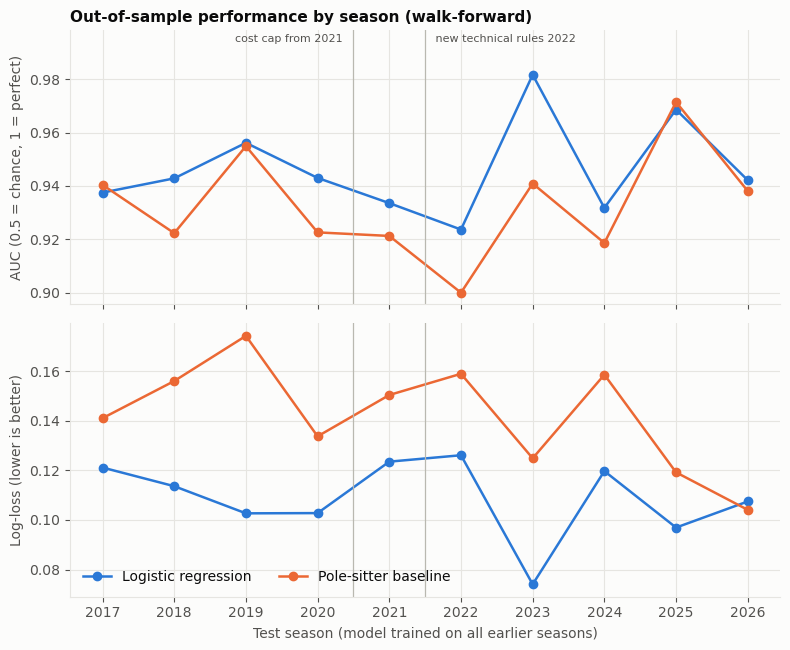

In [12]:
results = modeling.walk_forward(data, main)
display(results.round(3))
plots.save_table(results.round(3).set_index("year"), "walk_forward_main.csv")

fig = plots.plot_metrics_by_season(results)
plots.save_figure(fig, "metrics_by_season.png")

*Figure.* AUC (top) and log-loss (bottom) for each test season, for the logistic regression and for the pole-sitter baseline.
Vertical lines mark the start of the cost cap (2021) and of the new technical rules (2022).
Each season has about 20 to 24 races, so single-season values are noisy.

## 2. Robustness: other sets of features

The same walk-forward evaluation with fewer or more variables, averaged over each period.

In [13]:
ablation = modeling.ablation_table(data)
display(ablation)
plots.save_table(ablation, "feature_sets_by_period.csv")

AUC  log_loss  top_pick_hit
model                     period                                       
4 features (project spec) 2026 new rules  0.942     0.107         0.500
                          extension 2025  0.969     0.097         0.458
                          post-cap        0.943     0.111         0.534
                          pre-cap         0.945     0.110         0.536
6 features (current)      2026 new rules  0.949     0.102         0.550
                          extension 2025  0.969     0.094         0.375
                          post-cap        0.944     0.110         0.545
                          pre-cap         0.946     0.110         0.524
grid + driver form only   2026 new rules  0.944     0.104         0.450
                          extension 2025  0.968     0.097         0.500
                          post-cap        0.943     0.109         0.524
                          pre-cap         0.946     0.111         0.556
grid only                 2026 new rules  0.938     0.110         0.700
                          extension 2025  0.971     0.096         0.667
                          post-cap        0.920     0.129         0.512
                          pre-cap         0.935     0.119         0.499

## 3. Did performance change after the cost cap?

Out-of-sample predictions for 2017-2024 are split into 2017-2020 (before the cap) and 2021-2024 (after).
The bootstrap resamples whole races inside each period and gives a 95% interval for *after minus before*.
An interval that contains 0 means that no change can be detected with these data, which is a valid finding.

diff  ci_low  ci_high
model                     metric                          
6 features (current)      AUC      -0.002  -0.029    0.030
                          log_loss  0.000  -0.024    0.024
4 features (project spec) AUC      -0.002  -0.030    0.030
                          log_loss  0.001  -0.024    0.023
grid + driver form only   AUC      -0.001  -0.029    0.029
                          log_loss -0.001  -0.023    0.019
grid only                 AUC      -0.016  -0.052    0.023
                          log_loss  0.010  -0.015    0.034

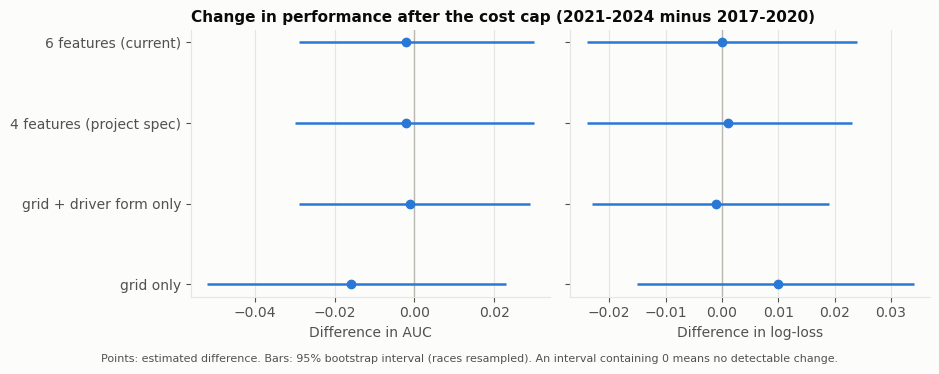

In [14]:
diffs = {name: modeling.bootstrap_diff(modeling.walk_forward_predictions(data, feats))
         for name, feats in modeling.FEATURE_SETS.items()}
diff_table = pd.concat(diffs, names=["model", "metric"])
display(diff_table)
plots.save_table(diff_table, "pre_post_cap_differences.csv")

fig = plots.plot_period_differences(diffs)
plots.save_figure(fig, "pre_post_differences.png")

*Figure.* Difference in AUC and in log-loss between 2021-2024 and 2017-2020 for each set of features, with 95% bootstrap intervals.
A positive AUC difference or a negative log-loss difference would mean better predictions after the cap.
A change after 2021 cannot be attributed to the cost cap alone, because the technical rules also changed in 2022.

## 4. Do the weights change after 2021?

One logistic regression on 2014-2024 with a post-2021 indicator and its interaction with each variable.
Variables are standardised, so weights are comparable. A row ending in *change after 2021* is the interaction term.
Intervals come from the race-level bootstrap. Two checks address the 2022 rule change:
dropping 2022, and using only 2021 as the post-cap period (only one season, so the intervals are very wide).

All seasons 2014-2024


,coef,ci_low,ci_high
grid,-3.31,-4.93,-1.98
driver_form3,0.48,0.15,0.73
driver_wins_before,0.34,0.15,0.55
team_pace3,-0.19,-1.46,0.20
grid_x_post,1.12,-0.98,3.10
driver_form3_x_post,0.56,0.13,1.11
driver_wins_before_x_post,-0.25,-0.52,0.00
team_pace3_x_post,-0.09,-1.50,1.54
post_cap,0.92,-1.49,3.35


Without 2022 (new technical rules)


,coef,ci_low,ci_high
grid_x_post,1.11,-1.57,3.28
driver_form3_x_post,0.59,0.10,1.19
driver_wins_before_x_post,-0.21,-0.50,0.06
team_pace3_x_post,0.06,-1.76,1.93
post_cap,0.96,-2.53,3.74


Only 2021 as post-cap (cap without the new cars)


,coef,ci_low,ci_high
grid_x_post,0.68,-5.91,2.93
driver_form3_x_post,-0.03,-0.66,0.88
driver_wins_before_x_post,-0.13,-0.57,0.18
team_pace3_x_post,0.42,-2.45,2.70
post_cap,1.59,-7.47,3.95


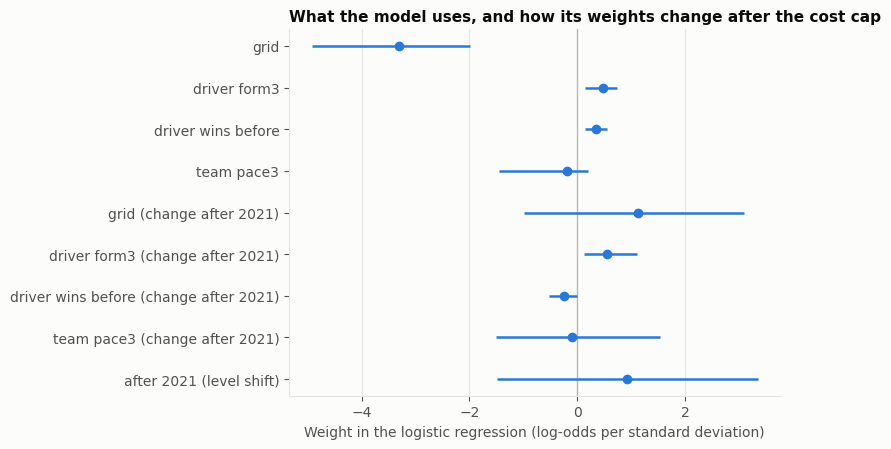

In [15]:
shown = ["grid_x_post", "driver_form3_x_post", "driver_wins_before_x_post", "team_pace3_x_post", "post_cap"]
sample = data[data["year"].between(2014, 2024)]

full = modeling.interaction_table(sample, main)
no_2022 = modeling.interaction_table(sample[sample["year"] != 2022], main).loc[shown]
only_2021 = modeling.interaction_table(sample[sample["year"] <= 2021], main).loc[shown]

print("All seasons 2014-2024");                       display(full)
print("Without 2022 (new technical rules)");          display(no_2022)
print("Only 2021 as post-cap (cap without the new cars)"); display(only_2021)

plots.save_table(full, "interactions_2014_2024.csv")
plots.save_table(no_2022, "interactions_without_2022.csv")
plots.save_table(only_2021, "interactions_only_2021.csv")

fig = plots.plot_coefficients(full)
plots.save_figure(fig, "coefficients.png")

*Figure.* Weights of the model (top four rows) and how they change after 2021 (bottom five rows), in log-odds per standard deviation,
with 95% bootstrap intervals. A negative weight on the grid means that a worse starting position lowers the probability of winning.
Intervals that contain 0 are not distinguishable from no effect or no change.

## 5. Model against the pole-sitter baseline

Log-loss of the model minus log-loss of the baseline, by period, with race-level bootstrap intervals.
Negative means that the model is better. The 2025 and 2026 seasons are an extension with data from a second source (Jolpica-F1);
2026 has new technical rules and only 20 races.

,period,gap,ci_low,ci_high
0,2026 new rules,0.0034,-0.0347,0.0399
1,extension 2025,-0.0223,-0.0555,0.0117
2,post-cap,-0.0374,-0.0556,-0.0193
3,pre-cap,-0.0420,-0.0619,-0.0215


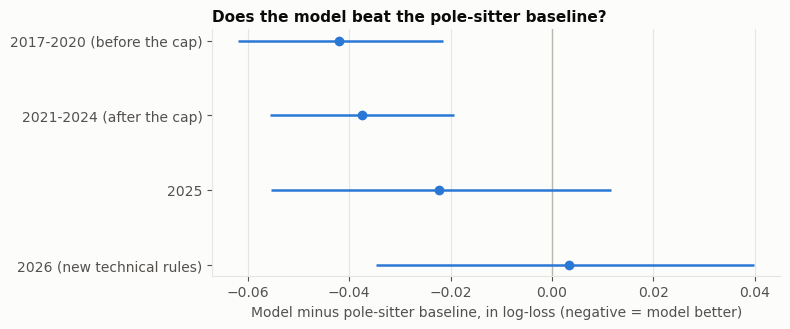

In [16]:
gap = modeling.baseline_gap_by_period(data, main)
display(gap)
plots.save_table(gap.set_index("period"), "model_vs_pole_baseline.csv")

fig = plots.plot_baseline_gap(gap)
plots.save_figure(fig, "baseline_gap.png")

*Figure.* Difference in log-loss between the model and the pole-sitter baseline in each period, with 95% bootstrap intervals.
An interval entirely below 0 means that the model beats the baseline in a way that is not due to chance alone.

In [17]:
full_1000 = modeling.interaction_table(sample, main, n_boot=1000).loc[shown]
no_2023 = modeling.interaction_table(sample[sample["year"] != 2023], main, n_boot=1000).loc[shown]
print("All seasons, 1000 resamples"); display(full_1000)
print("Without 2023 (Red Bull 21 wins out of 22)"); display(no_2023)

All seasons, 1000 resamples


,coef,ci_low,ci_high
grid_x_post,1.12,-1.01,3.22
driver_form3_x_post,0.56,0.12,1.14
driver_wins_before_x_post,-0.25,-0.52,0.01
team_pace3_x_post,-0.09,-1.61,1.62
post_cap,0.92,-1.63,3.57


Without 2023 (Red Bull 21 wins out of 22)


,coef,ci_low,ci_high
grid_x_post,1.17,-1.14,3.22
driver_form3_x_post,0.20,-0.28,0.73
driver_wins_before_x_post,-0.21,-0.47,0.03
team_pace3_x_post,-0.20,-1.59,1.38
post_cap,1.41,-1.16,3.96


In [18]:
plots.save_table(full_1000, "interactions_1000_resamples.csv")
plots.save_table(no_2023, "interactions_without_2023.csv")